# Visualizaciones: Tarea 3
**Introducción a Ciencia de Datos para Economía** - Equipo 2

En la primer sección, observamos la limpieza y tratamiento de la base de datos de 124,261 registros y 14 columnas; en la que se describen los incidentes reportados al C5 de la ciudad de México. Algunos puntos importantes a destacar son los siguientes:
- Las observaciones van del 2021-12-31 20:59:59 al 2024-02-29 23:58:48.
- De los reportes, únicamente 4 se encuentran fuera de la Ciudad de México.

Se decidió no eliminar ninguna de las observaciones para mantener la integridad de los datos que nos fueron proporcionados. Asimismo, se hacen conversiones sobre las variables temporales para poder utilizarlas de forma adecuada en los análisis y visualizaciones subsecuentes.

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

url = 'https://raw.githubusercontent.com/ElenaVillano/databases/refs/heads/main/db_falsas_alarmas.csv'
df = pd.read_csv(url)
df['fecha_hora_creacion'] = pd.to_datetime(df['fecha_hora_creacion'])
df['fecha_hora_cierre'] = pd.to_datetime(df['fecha_hora_cierre'])
creacion = df['fecha_hora_creacion']
duracion_en_horas = (df['fecha_hora_cierre'] - creacion).dt.total_seconds() / 3600
mes = creacion.dt.to_period('M').dt.to_timestamp() 

# Estilo base
sns.set_theme(style='whitegrid', palette='crest')

# Colores y nombres
nombres = {'A': 'Afirmativo (A)', 'D': 'Duplicado (D)', 'F': 'Falso (F)', 'I': 'Informativo (I)'}
colores = {'Afirmativo (A)': '#7BC8A4', 'Duplicado (D)': '#7AA6DC', 'Falso (F)': '#f7bd56', 'Informativo (I)': '#C3A6E0'}

## Preguntas de análisis

Para esta sección, estaremos contestando a las siguientes preguntas, las cuales consideramos importantes para visualizar el problema adecuadamente:

**¿Cómo cambia mes a mes la proporción de reportes que termina con cada código de cierre?**

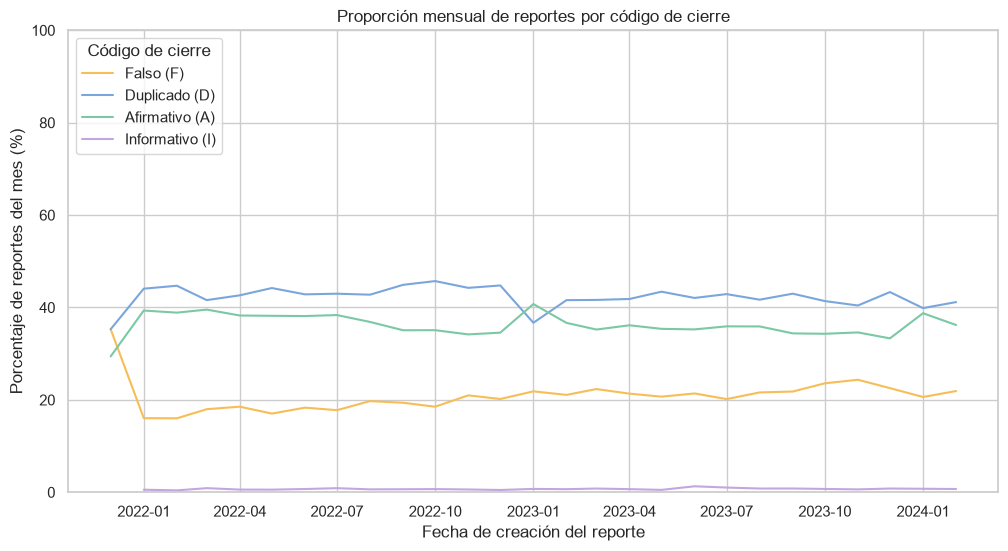

In [23]:
por_mes = (df.groupby(mes)['codigo_cierre'].value_counts(normalize=True).mul(100).rename('porcentaje').reset_index()
)
por_mes['codigo_cierre'] = por_mes['codigo_cierre'].map(nombres)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=por_mes,
    x='fecha_hora_creacion',
    y='porcentaje',
    hue='codigo_cierre',
    palette=colores
)

plt.xlabel('Fecha de creación del reporte')
plt.ylabel('Porcentaje de reportes del mes (%)')
plt.title('Proporción mensual de reportes por código de cierre')
plt.ylim(0, 100)

plt.legend(
    title='Código de cierre',
    loc='upper left'
)

plt.show()

Con esta gráfica, podemos observar que las falsas alertas tienen una tendencia al alza, comenzando por debajo del 20% al inicio del periodo de análisis y terminando por encima de este valor al final del periodo de análisis. 

Asímismo, los duplicados y los informativos parecen mantenerse estables a lo largo del tiempo; por lo que el incremento en la proporción de falsas alarmas impacta negativamente a la proporción de confirmados, los cuales observan una tendencia a la baja.

**¿Cómo cambia el número de reportes según el día de la semana y la hora?**

C:\Users\ivann\AppData\Local\Temp\ipykernel_38056\2632085700.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  dia_semana = creacion.dt.dayofweek.map(dict(enumerate(dias)))


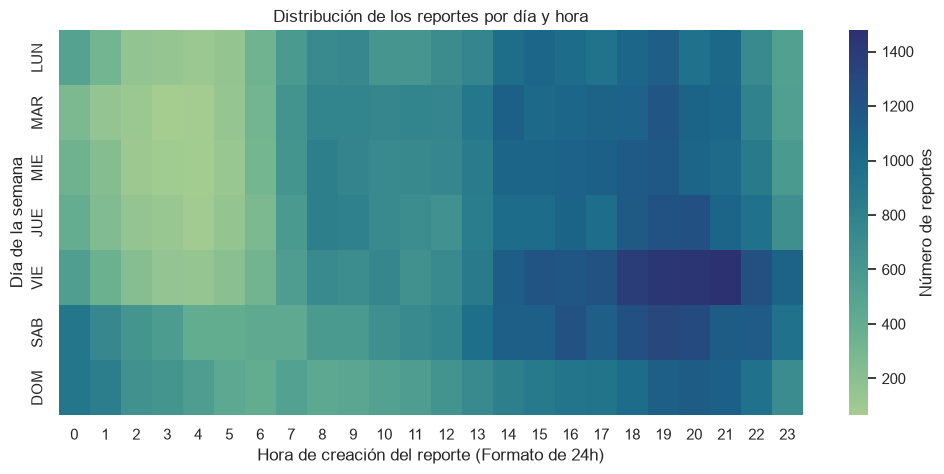

In [25]:
dias = ['LUN', 'MAR', 'MIE', 'JUE', 'VIE', 'SAB', 'DOM']
dia_semana = creacion.dt.dayofweek.map(dict(enumerate(dias)))
reportes_dia_hora = pd.crosstab(dia_semana, creacion.dt.hour).loc[dias]

plt.figure(figsize=(12, 5))

sns.heatmap(
    reportes_dia_hora,
    cmap='crest',
    cbar_kws={'label': 'Número de reportes'}
)

plt.xlabel('Hora de creación del reporte (Formato de 24h)')
plt.ylabel('Día de la semana')
plt.title('Distribución de los reportes por día y hora')

plt.show()

Se observa que el día de la semana y la hora de los incidentes influye en el conteo de los mismos. Observando que de 2 a 6 de la mañana los días martes y miércoles parecen ser los menos activos en cuanto al número de reportes; mientras que entre las 19 y las 22 horas del viernes, los reportes incrementan. Esto tiene sentido si pensamos en la que hay más actividad en las calles los días viernes por la noche que los días martes por la mañana.

**¿Qué proporción de los reportes de cada canal de aviso resulta ser una falsa alarma?**

C:\Users\ivann\AppData\Local\Temp\ipykernel_38056\3880667578.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


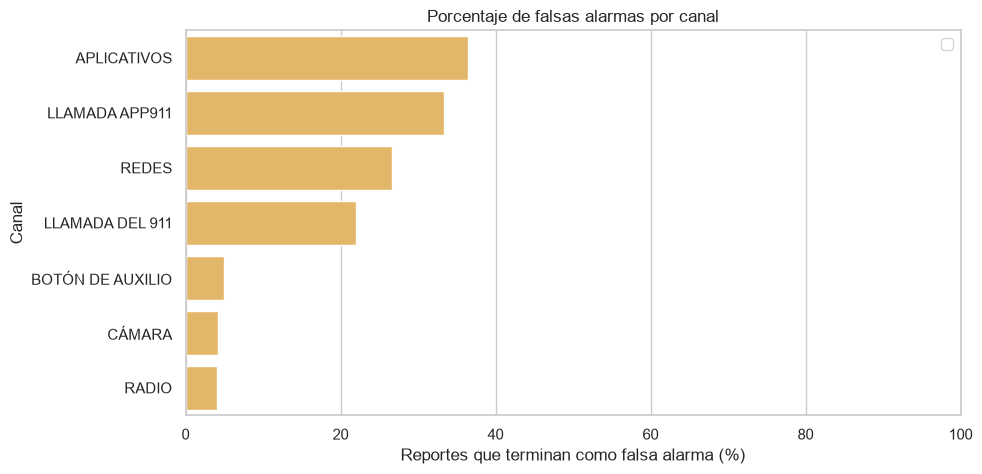

In [26]:
canal = df.groupby('tipo_entrada').agg(reportes=('folio', 'size'))
canal['porcentaje_falsas'] = (df['codigo_cierre'] == 'F').groupby(df['tipo_entrada']).mean() * 100
canal = canal.sort_values('porcentaje_falsas', ascending=False).reset_index()

porcentaje_global = (df['codigo_cierre'] == 'F').mean() * 100
plt.figure(figsize=(10, 5))
sns.barplot(
    data=canal,
    x='porcentaje_falsas',
    y='tipo_entrada',
    color=colores['Falso (F)']
)

plt.xlabel('Reportes que terminan como falsa alarma (%)')
plt.ylabel('Canal')
plt.title('Porcentaje de falsas alarmas por canal')
plt.xlim(0, 100)
plt.legend()

plt.show()

De esta distribución, podemos ver que la concentración de los reportes o informes que terminan en una falsa alarma se dan principalmente en los canales donde la gente es quien hace el reporte (llamadas al 911 o el uso de la aplicación); mientras que sistemas como la cámara o los botones de auxilio tienen menos tendencia a ser falsos. Esto tiene sentido pensando en que una persona puede confundirse al momento del reporte, pero las cámaras observan y reportan de forma objetiva a las centrales.

**¿Cómo se reparten los códigos de cierre dentro de cada tipo de incidente?**

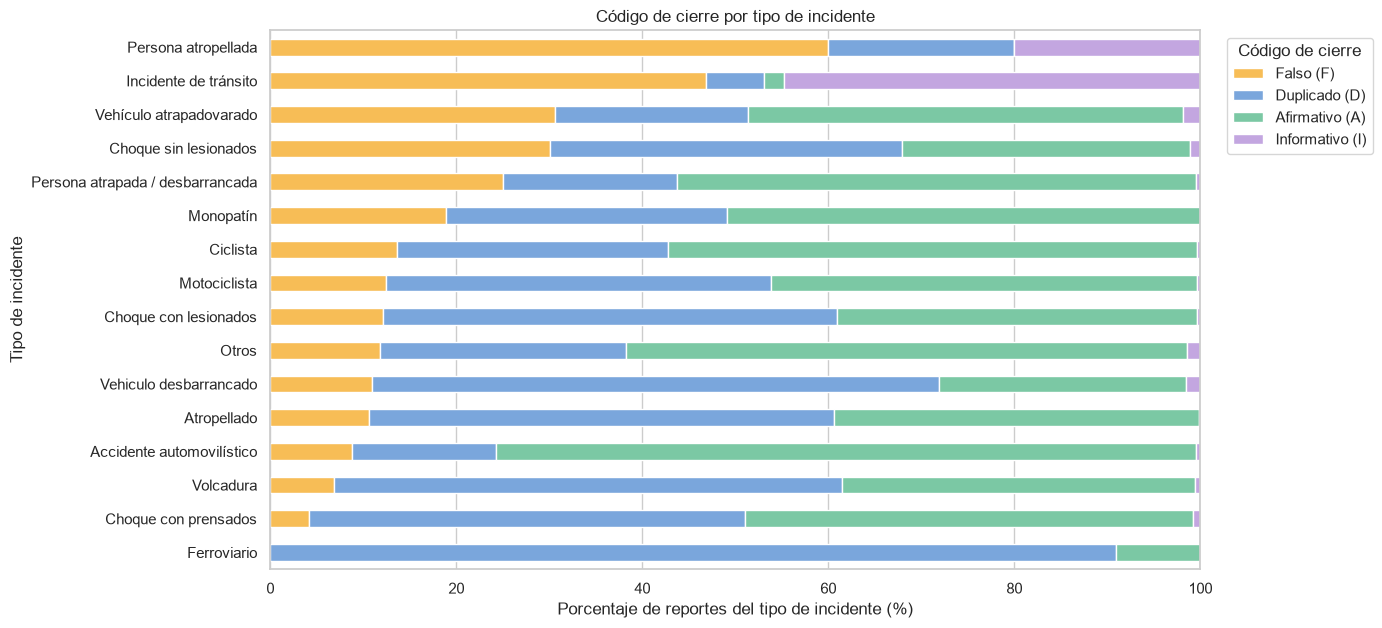

In [27]:
composicion = pd.crosstab(df['incidente_c4'], df['codigo_cierre'], normalize='index') * 100
composicion = composicion.rename(columns=nombres)
composicion = composicion[['Falso (F)', 'Duplicado (D)', 'Afirmativo (A)', 'Informativo (I)']].sort_values('Falso (F)')

composicion.plot(
    kind='barh',
    stacked=True,
    figsize=(12, 7),
    color=colores
)

plt.xlabel('Porcentaje de reportes del tipo de incidente (%)')
plt.ylabel('Tipo de incidente')
plt.title('Código de cierre por tipo de incidente')
plt.xlim(0, 100)

plt.legend(
    title='Código de cierre',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.show()

De este gráfico podemos aislar dos cosas importantes:
- Las personas atropelladas son de los reportes que tienen más cierres como falsos. Lo anterior puede deberse a que las personas reportan que vieron algun atropellamiento, pero la vista pudo haberlos engañado y no haber tenido heridos.
- Los accidentes que involucran lesionados son los que tienen un mayor número de duplicados. Lo anterior puede deberse a multiples reportes de diferentes testigos, donde cada uno levanta un reporte diferente para "agilizar" la atencióin de los heridos. 

**¿Cuánto tiempo pasa entre la creación y el cierre de un reporte, y depende del código de cierre?**

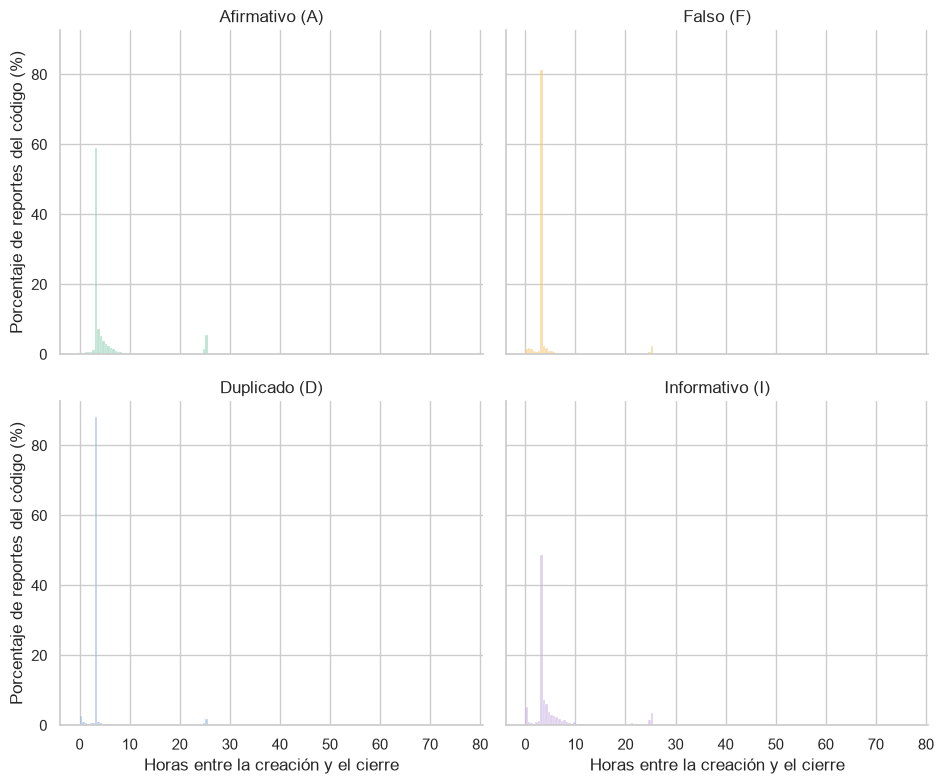

In [ ]:
tiempos = pd.DataFrame({
    'duracion_h': duracion_h,
    'codigo_cierre': df['codigo_cierre'].map(nombres)
})

g = sns.displot(
    data=tiempos,
    x='duracion_h',
    col='codigo_cierre',
    hue='codigo_cierre',
    palette=colores,
    col_wrap=2,
    binwidth=0.5,
    stat='percent',
    common_norm=False,
    height=4,
    aspect=1.2,
    legend=False
)

g.set_axis_labels('Horas','Porcentaje de reportes (%)')
g.set_titles('{col_name}')
plt.show()

Por lo que se observa, casi todos los incidentes se cierran en la misma cantidad de tiempo, independientemente de la naturaleza del informe. Esto puede ser relevante ya que el tiempo transcurrido entre la creación y el cierre de un informe podría no agregar información en un modelo de predicción.

**¿Cómo ha cambiado con el tiempo la proporción de reportes que tardan más de 24 horas en cerrarse?**

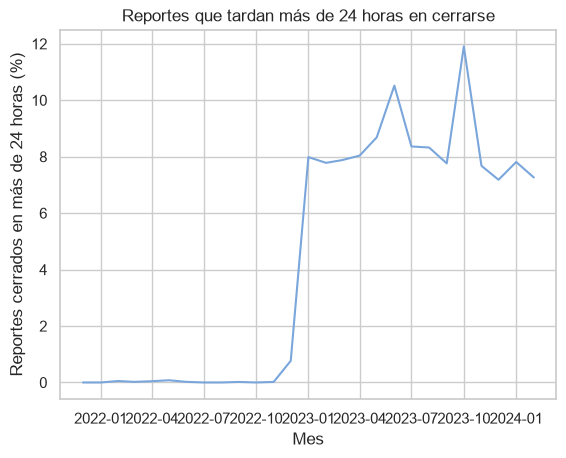

In [32]:
mas_de_24h = ((duracion_h > 24).groupby(mes).mean() * 100).rename('porcentaje').reset_index()

sns.lineplot(
    data=mas_de_24h,
    x='fecha_hora_creacion',
    y='porcentaje',
    color=colores['Duplicado (D)']
)

plt.xlabel('Mes')
plt.ylabel('Reportes cerrados en más de 24 horas (%)')
plt.title('Reportes que tardan más de 24 horas en cerrarse')

plt.show()

Se observa un incremento fuerte en el número de reportes que se cierran en más de 24 horas a partir de 2023, lo que sugiere que en esas fechas hubo un cambio estructural relevante, ya sea un cambio administrativo, operativo o que haya impactado la medición de los tiempos. Sin embargo, será importante aclarar el por qué de este incremento.

**¿Cómo varía la proporción de falsas alarmas entre alcaldías?**

C:\Users\ivann\AppData\Local\Temp\ipykernel_38056\1707910195.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


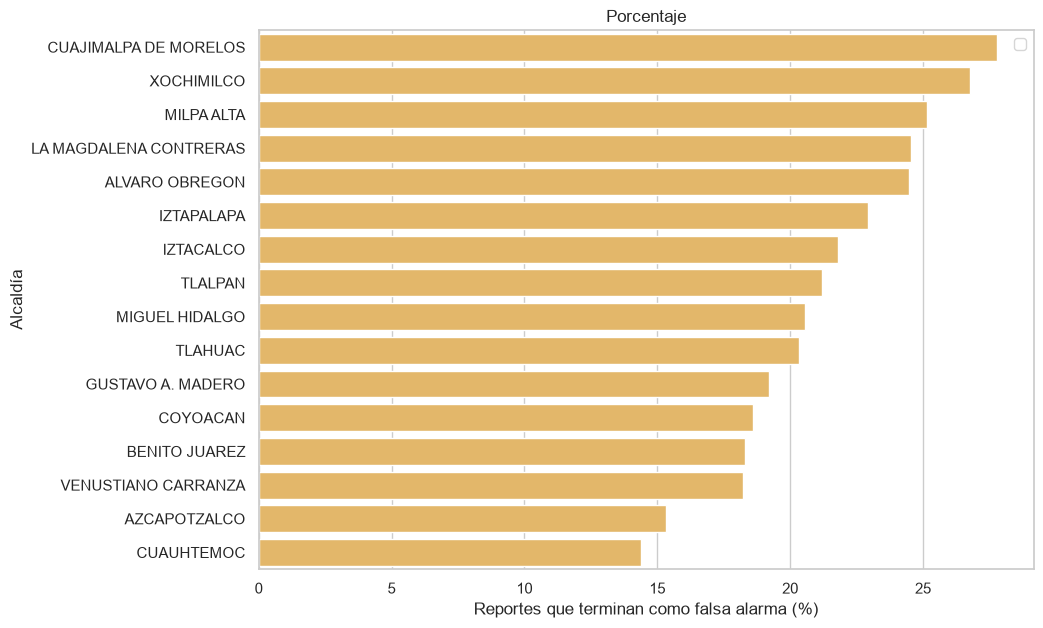

In [34]:
alcaldia = df.groupby('alcaldia_inicio').agg(reportes=('folio', 'size'))
alcaldia['porcentaje_falsas'] = (df['codigo_cierre'] == 'F').groupby(df['alcaldia_inicio']).mean() * 100
alcaldia = alcaldia.sort_values('porcentaje_falsas', ascending=False).reset_index()

plt.figure(figsize=(10, 7))

sns.barplot(
    data=alcaldia,
    x='porcentaje_falsas',
    y='alcaldia_inicio',
    color=colores['Falso (F)']
)

plt.xlabel('Reportes que terminan como falsa alarma (%)')
plt.ylabel('Alcaldía')
plt.title('Porcentaje')
plt.legend()

plt.show()

En proporción al número total de reportes que se hacen en cada una de las alcaldías, vemos que Cuajimalpa, Xochimilco y Milpa Alta componen el Top 3 de las alcaldías en que los reportes se cierran como falsas alarmas. Esto puede arrojar un sesgo dependiendo de como se trate la información, ya que un modelo podría "desconfiar" de estas alcaldías simplemente por tener una concentración más elevada de reportes que se cierran como "falsas alarmas". Podría haber una implicación ética al utilizar esta variable de forma inadecuada.

**¿Dónde se ubican los reportes de incidentes viales?**

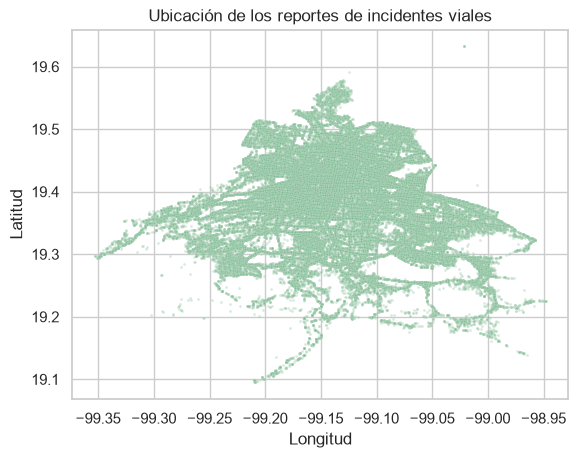

In [35]:
sns.scatterplot(
    data=df,
    x='longitud',
    y='latitud',
    s=4,
    alpha=0.3
)

plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.title('Ubicación de los reportes de incidentes viales')

plt.show()

Las coordenadas dibujan la CDMX, concentrandose principalmente en la zona centro, dejando las periferias en blanco. Nuevamente, esto puede deberse a que los reportes normalmente toman vialidades principales como referencia para los reportes, y las vialidades secundarias o de zonas no céntricas quedan relegadas.